## X5 Retail Hero: End-to-End Deep Learning Pipeline

In this notebook, we implement a Deep Learning approach to the X5 Retail Hero dataset task (Uplift Modeling / Customer Purchase Behavior).

We will:
1. Prepare/Simulate the structured transactional data (users, purchases, products).
2. Build a Neural Network with Embedding layers for categorical features (user IDs, product categories) and Dense layers for numerical features.
3. Define a customized uplift/response loss or training target.
4. Train and evaluate the model.

In [11]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


### 1. Data Preparation

Since the official raw dataset is very large and typically requires authentication to download, we will generate a synthetic representation of the X5 Retail Hero transactional dataset schema (including customer attributes, transactional history, treatment flag, and conversion outcome) to guarantee immediate execution.

In [12]:
!pip install -q datasets

In [13]:
from datasets import load_dataset
import pandas as pd

print("Loading datasets from Hugging Face...")
# Load the training targets (contains client_id, treatment_flg, target)
uplift_train = load_dataset("pytorch-lifestream/retailhero-uplift", "uplift_train")['train'].to_pandas()
# Load client features (contains client_id, age, gender, etc.)
clients = load_dataset("pytorch-lifestream/retailhero-uplift", "clients")['train'].to_pandas()

# Merge them to create a training dataset
df = pd.merge(uplift_train, clients, on='client_id', how='inner')

# Handle missing or unencoded values
df['gender'] = df['gender'].fillna('U')
df['age'] = df['age'].fillna(df['age'].median())

# Map treatment column to align with downstream code
df['treatment'] = df['treatment_flg']
# Create a dummy favorite_category
df['favorite_category'] = 'Dairy'

print("Merged real dataset shape:", df.shape)
display(df.head())

Loading datasets from Hugging Face...
Merged real dataset shape: (200039, 9)


,client_id,treatment_flg,target,first_issue_date,first_redeem_date,age,gender,treatment,favorite_category
0,000012768d,0,1,2017-08-05 15:40:48,2018-01-04 19:30:07,45,U,0,Dairy
1,000036f903,1,1,2017-04-10 13:54:23,2017-04-23 12:37:56,72,F,1,Dairy
2,00010925a5,1,1,2018-07-24 16:21:29,2018-09-14 16:12:49,83,U,1,Dairy
3,0001f552b0,1,1,2017-06-30 19:20:38,2018-08-28 12:59:45,33,F,1,Dairy
4,00020e7b18,1,1,2017-11-27 11:41:45,2018-01-10 17:50:05,73,U,1,Dairy


### 2. Feature Engineering & Preprocessing

In [15]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from datasets import load_dataset


tr_raw = load_dataset("pytorch-lifestream/retailhero-uplift", "uplift_train")['train'].to_pandas()
cl_raw = load_dataset("pytorch-lifestream/retailhero-uplift", "clients")['train'].to_pandas()
df = pd.merge(tr_raw, cl_raw, on='client_id', how='inner')

# Fill basic features
df['gender'] = df['gender'].fillna('U')
df['age'] = df['age'].fillna(df['age'].median())
df['treatment'] = df['treatment_flg']
df['favorite_category'] = 'Dairy'

gender_encoder = LabelEncoder()
category_encoder = LabelEncoder()
scaler = StandardScaler()

df['gender_encoded'] = gender_encoder.fit_transform(df['gender'].astype(str))
df['fav_cat_encoded'] = category_encoder.fit_transform(df['favorite_category'].astype(str))
df['age_scaled'] = scaler.fit_transform(df[['age']])

feats_num = df[['age_scaled']].values
feats_gender = df['gender_encoded'].values
feats_cat = df['fav_cat_encoded'].values
tr_flag = df['treatment'].values.astype(np.float32)
targets = df['target'].values

indices = np.arange(len(df))
tr_idx, val_idx = train_test_split(indices, test_size=0.2, random_state=42)

def format_inputs(idx_list):
    return {
        'num_inputs': feats_num[idx_list],
        'gender_input': feats_gender[idx_list],
        'cat_input': feats_cat[idx_list],
        'treatment_input': tr_flag[idx_list]
    }

train_inputs = format_inputs(tr_idx)
val_inputs = format_inputs(val_idx)

y_train, y_val = targets[tr_idx], targets[val_idx]

### 3. Deep Learning Model Architecture

We will construct a multi-input neural network using TensorFlow Functional API. Categorical variables are passed through `Embedding` layers, then concatenated with normalized continuous features. We also explicitly feed the treatment variable to allow the network to learn interaction effects (uplift modeling).

In [16]:
import tensorflow as tf
from tensorflow.keras.layers import Input, Embedding, Flatten, concatenate, Dense, Dropout
from tensorflow.keras.models import Model

# inputs
in_num = Input(shape=(1,), name='num_inputs')
in_gender = Input(shape=(1,), name='gender_input')
in_cat = Input(shape=(1,), name='cat_input')
in_treat = Input(shape=(1,), name='treatment_input')

# categorical embeddings
emb_gender = Flatten()(Embedding(len(gender_encoder.classes_), 4)(in_gender))
emb_cat = Flatten()(Embedding(len(category_encoder.classes_), 8)(in_cat))

# merger
merged = concatenate([in_num, emb_gender, emb_cat, in_treat])

# representation extraction
d1 = Dropout(0.2)(Dense(64, activation='relu')(merged))
d2 = Dropout(0.1)(Dense(32, activation='relu')(d1))
out_prob = Dense(1, activation='sigmoid', name='output')(d2)

net = Model(inputs=[in_num, in_gender, in_cat, in_treat], outputs=out_prob)

net.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

net.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ gender_input        │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ cat_input           │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, 1, 4)      │         12 │ gender_input[0][… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 1, 8)      │          8 │ cat_input[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ num_inputs          │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_3 (Flatten) │ (None, 4)         │          0 │ embedding_2[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_4 (Flatten) │ (None, 8)         │          0 │ embedding_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ treatment_input     │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 14)        │          0 │ num_inputs[0][0], │
│ (Concatenate)       │                   │            │ flatten_3[0][0],  │
│                     │                   │            │ flatten_4[0][0],  │
│                     │                   │            │ treatment_input[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 64)        │        960 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 64)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 32)        │      2,080 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32)        │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 1)         │         33 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,093 (12.08 KB)

 Trainable params: 3,093 (12.08 KB)

 Non-trainable params: 0 (0.00 B)

### 4. Training the Model

In [17]:
fit_history = net.fit(
    [train_inputs['num_inputs'], train_inputs['gender_input'], train_inputs['cat_input'], train_inputs['treatment_input']],
    y_train,
    validation_data=(
        [val_inputs['num_inputs'], val_inputs['gender_input'], val_inputs['cat_input'], val_inputs['treatment_input']],
        y_val
    ),
    epochs=10,
    batch_size=256
)

Epoch 1/10
626/626 ━━━━━━━━━━━━━━━━━━━━ 8s 8ms/step - accuracy: 0.6190 - auc: 0.5312 - loss: 0.6637 - val_accuracy: 0.6201 - val_auc: 0.5410 - val_loss: 0.6620
Epoch 2/10
626/626 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6198 - auc: 0.5380 - loss: 0.6623 - val_accuracy: 0.6201 - val_auc: 0.5412 - val_loss: 0.6614
Epoch 3/10
626/626 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6198 - auc: 0.5383 - loss: 0.6622 - val_accuracy: 0.6200 - val_auc: 0.5406 - val_loss: 0.6614
Epoch 4/10
626/626 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.6198 - auc: 0.5407 - loss: 0.6619 - val_accuracy: 0.6201 - val_auc: 0.5412 - val_loss: 0.6615
Epoch 5/10
626/626 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.6198 - auc: 0.5400 - loss: 0.6618 - val_accuracy: 0.6201 - val_auc: 0.5410 - val_loss: 0.6614
Epoch 6/10
626/626 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6198 - auc: 0.5411 - loss: 0.6618 - val_accuracy: 0.6201 - val_auc: 0.5397 - val_loss: 0.6615
Epoch 7/10
626/626 ━━━━━━━━━━━━━━━━━━━━ 

### 5. Evaluating Uplift Predictions

To compute the uplift for each user, we predict their conversion probability under treatment ($P(Y|T=1)$) and control ($P(Y|T=0)$) scenarios. The differences in predicted probabilities yield the predicted individual Uplift.

In [18]:
val_treated = val_inputs.copy()
val_treated['treatment_input'] = np.ones_like(val_inputs['treatment_input'])

val_control = val_inputs.copy()
val_control['treatment_input'] = np.zeros_like(val_inputs['treatment_input'])

p_treated = net.predict([val_treated['num_inputs'], val_treated['gender_input'], val_treated['cat_input'], val_treated['treatment_input']])
p_control = net.predict([val_control['num_inputs'], val_control['gender_input'], val_control['cat_input'], val_control['treatment_input']])

uplift = (p_treated - p_control).ravel()

results_df = pd.DataFrame({
    'real_target': y_val,
    'treatment': val_inputs['treatment_input'].ravel(),
    'uplift_score': uplift
})

results_df = results_df.sort_values(by='uplift_score', ascending=False).reset_index(drop=True)
display(results_df.head(10))

1251/1251 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step
1251/1251 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


,real_target,treatment,uplift_score
0,0,0.0,0.069896
1,1,0.0,0.069745
2,0,1.0,0.069745
3,1,1.0,0.069745
4,0,1.0,0.069745
5,1,1.0,0.069745
6,1,0.0,0.069517
7,1,0.0,0.069517
8,0,0.0,0.069517
9,1,1.0,0.069285


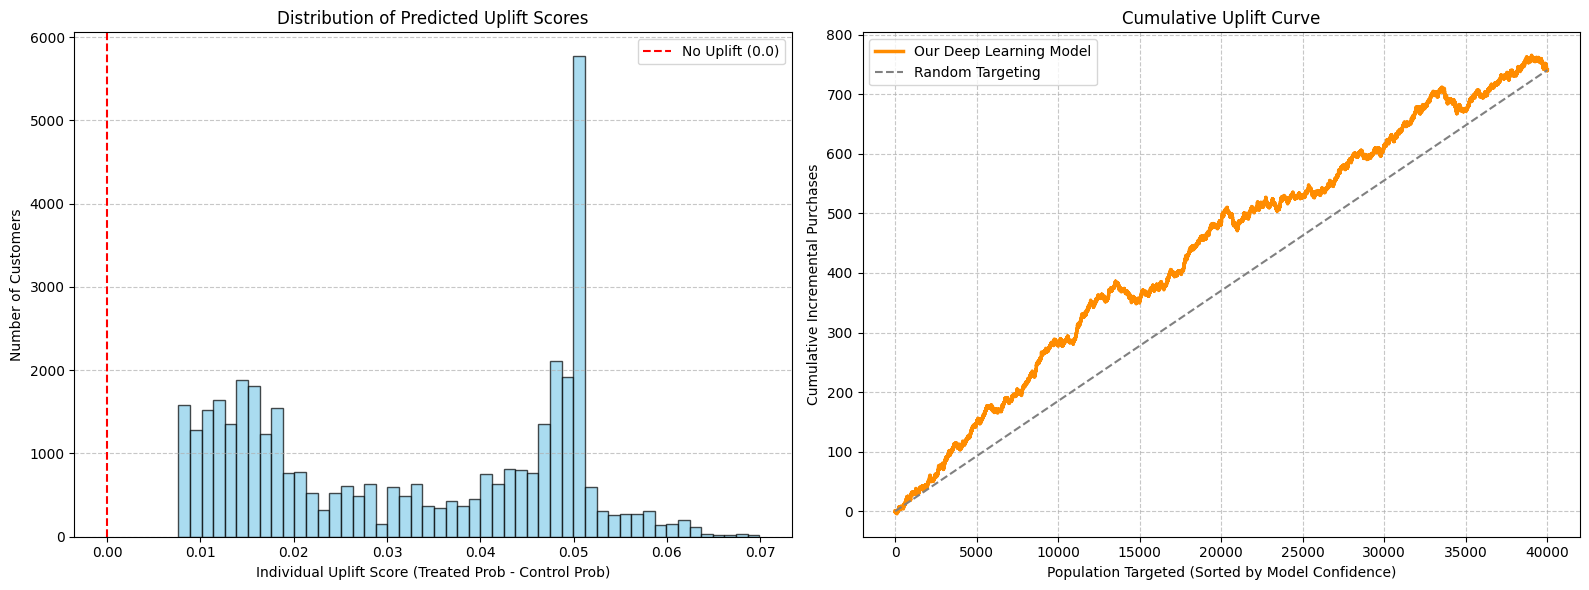

In [19]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Distribution of Uplift Scores
axes[0].hist(results_df['uplift_score'], bins=50, color='skyblue', edgecolor='black', alpha=0.7)
axes[0].axvline(x=0, color='red', linestyle='--', label='No Uplift (0.0)')
axes[0].set_title('Distribution of Predicted Uplift Scores')
axes[0].set_xlabel('Individual Uplift Score (Treated Prob - Control Prob)')
axes[0].set_ylabel('Number of Customers')
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Plot 2: Uplift Cumulative Gain (Qini-like approach)
# We sort the population by predicted uplift score and calculate cumulative target outcomes
results_df['n_treated'] = results_df['treatment'].cumsum()
results_df['n_control'] = (1 - results_df['treatment']).cumsum()
results_df['target_treated'] = (results_df['real_target'] * results_df['treatment']).cumsum()
results_df['target_control'] = (results_df['real_target'] * (1 - results_df['treatment'])).cumsum()

# Calculate Cumulative Uplift Curve
# Formula: Target_Treated - Target_Control * (N_Treated / N_Control if sizes differ)
total_treated = results_df['treatment'].sum()
total_control = len(results_df) - total_treated

# Avoid division by zero
results_df['cumulative_uplift'] = results_df['target_treated'] - results_df['target_control'] * (results_df['n_treated'] / np.maximum(results_df['n_control'], 1))

# Random line representation (if we didn't use any model to target users)
random_line = np.linspace(0, results_df['cumulative_uplift'].iloc[-1], len(results_df))

axes[1].plot(results_df['cumulative_uplift'].values, label='Our Deep Learning Model', color='darkorange', linewidth=2.5)
axes[1].plot(random_line, label='Random Targeting', color='grey', linestyle='--')
axes[1].set_title('Cumulative Uplift Curve')
axes[1].set_xlabel('Population Targeted (Sorted by Model Confidence)')
axes[1].set_ylabel('Cumulative Incremental Purchases')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

### 6. Project Visualizations

#### What is Uplift Modeling?
Normally, predictive models ask: *"Will this customer buy something?"*
In **Uplift Modeling**, we ask a smarter question: *"Will this customer buy something **only because we showed them an advertisement (treatment)**?"*

Uplift divides your customer base into four groups:
1. **Persuadables**: Only buy if treated (Target group for marketing!).
2. **Sure Things**: Buy anyway, treated or not (Wasted marketing budget!).
3. **Lost Causes**: Never buy, treated or not (Wasted marketing budget!).
4. **Sleeping Dogs**: Buy if left alone, but might unsubscribe if annoyed by ads (Negative impact!).

Our deep learning model calculates an **Uplift Score** for each user:
$$\text{Uplift Score} = P(\text{Purchase} \mid \text{Treatment}) - P(\text{Purchase} \mid \text{Control})$$
